# EDA sur Listings


## Imports

In [237]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import ast
from collections import Counter


chemin_airbnb = Path(r"C:/Users/mehdi/Documents/ProjetData/airbnb-price-prediction/data/raw/airbnb")
chemin_poi = Path(r"C:/Users/mehdi/Documents/ProjetData/airbnb-price-prediction/data/raw/poi")

In [238]:
df = pd.read_parquet(chemin_airbnb / "listings_detailled.parquet")

print("Le dataset contient", df.shape[0], "lignes et  ", df.shape[1], "colonnes.")


Le dataset contient 77149 lignes et   90 colonnes.


In [239]:
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,3109,https://www.airbnb.com/rooms/3109,20260916052215,2026-09-19,NaN,zen and calm,Lovely Appartment with one bedroom with a Quee...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,3631,...,5.00,5.00,4.90,7511409139079,NaN,1,1,0,0,0.09
1,7397,https://www.airbnb.com/rooms/7397,20260916052215,2026-09-22,NaN,MARAIS - 2ROOMS APT - 2/4 PEOPLE,"VERY CONVENIENT, WITH THE BEST LOCATION !",NaN,https://a0.muscache.com/pictures/67928287/330b...,2626,...,4.90,4.94,4.74,7510400829623,NaN,1,1,0,0,2.14
2,9952,https://www.airbnb.com/rooms/9952,20260916052215,2026-09-21,NaN,Paris petit coin douillet,"I am a retired lady, who offers a pleasant lit...",NaN,https://a0.muscache.com/pictures/ae822d16-74d2...,33534,...,4.87,4.87,4.88,7511101582862,NaN,1,1,0,0,0.36
3,11265,https://www.airbnb.com/rooms/11265,20260916052215,2026-09-22,NaN,Elegant appartment in Montmartre,"Located in lively and charming Montmartre, pla...",NaN,https://a0.muscache.com/pictures/miso/Hosting-...,41718,...,4.90,4.96,4.85,7511801401834,NaN,1,1,0,0,0.38
4,11487,https://www.airbnb.com/rooms/11487,20260916052215,2026-09-21,NaN,"Heart of Paris, brand new aparment.",Very confortable and bright studio (18m2). The...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,42666,...,4.95,4.95,4.71,"Available with a mobility lease only (""bail mo...",NaN,1,1,0,0,0.12


In [240]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 77149 entries, 0 to 77148
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            77149 non-null  int64  
 1   listing_url                                   77149 non-null  str    
 2   scrape_id                                     77149 non-null  int64  
 3   last_scraped                                  77149 non-null  str    
 4   source                                        33044 non-null  str    
 5   name                                          77149 non-null  str    
 6   description                                   76876 non-null  str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   77147 non-null  str    
 9   host_id                                       77149 non-null  int64  
 1

In [241]:
for column in df.columns:
    if df[column].nunique() <= 1:
        df.drop(columns=column, inplace=True)
        print(f'{column} - supprimée')

    else:
        print(f'\n{column}')
        print('Nombre de modalités :', df[column].nunique())
        print('Nombre de valeurs manquantes :', df[column].isna().sum())
        print('types :', df[column].dropna().map(type).unique())

        print('Modalités les plus fréquentes :')
        print(df[column].value_counts().head(5))

        print('Modalités les moins fréquentes :')
        print(df[column].value_counts().tail(5))


id
Nombre de modalités : 77149
Nombre de valeurs manquantes : 0
types : [<class 'int'>]
Modalités les plus fréquentes :
id
3109     1
7397     1
9952     1
11265    1
11487    1
Name: count, dtype: int64
Modalités les moins fréquentes :
id
1775393921523535909    1
1775399195823385727    1
1775408419703264483    1
1775445409530547879    1
1775503305421490832    1
Name: count, dtype: int64

listing_url
Nombre de modalités : 77149
Nombre de valeurs manquantes : 0
types : [<class 'str'>]
Modalités les plus fréquentes :
listing_url
https://www.airbnb.com/rooms/3109     1
https://www.airbnb.com/rooms/7397     1
https://www.airbnb.com/rooms/9952     1
https://www.airbnb.com/rooms/11265    1
https://www.airbnb.com/rooms/11487    1
Name: count, dtype: int64
Modalités les moins fréquentes :
listing_url
https://www.airbnb.com/rooms/1775393921523535909    1
https://www.airbnb.com/rooms/1775399195823385727    1
https://www.airbnb.com/rooms/1775408419703264483    1
https://www.airbnb.com/rooms/1775

C:\Users\mehdi\AppData\Local\Temp\ipykernel_20152\1978474536.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=column, inplace=True)


types : [<class 'str'>]
Modalités les plus fréquentes :
last_scraped
2026-09-18    26223
2026-09-21    15554
2026-09-20    12107
2026-09-22    10580
2026-09-19     9725
Name: count, dtype: int64
Modalités les moins fréquentes :
last_scraped
2026-09-22    10580
2026-09-19     9725
2026-09-17     2152
2026-09-23      805
2026-09-24        3
Name: count, dtype: int64
source - supprimée

name
Nombre de modalités : 72302
Nombre de valeurs manquantes : 0
types : [<class 'str'>]
Modalités les plus fréquentes :
name
Appartement                      78
Charmant appartement parisien    58
Appartement au cœur de Paris     47
Appartement Paris                46
Appartement Montmartre           41
Name: count, dtype: int64
Modalités les moins fréquentes :
name
Louvre-Rivoli, Studio Saint-Roch                      1
Luxury 1BDR/4P Apartment in the heart of Paris        1
Charmant appartement au coeur du Paris authentique    1
Luxury Apartment a few steps from Champs Elysées      1
Splendide appartem

C:\Users\mehdi\AppData\Local\Temp\ipykernel_20152\1978474536.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=column, inplace=True)


Nombre de modalités : 72243
Nombre de valeurs manquantes : 273
types : [<class 'str'>]
Modalités les plus fréquentes :
description
Our mission is to empower individuals to immerse themselves in new places by having a home wherever they go. To do this, we provide fully furnished and equipped apartments, artfully designed, for stays of one month or more. We are currently present in some of the most important cities in Europe.    175
Keep it simple at this peaceful and centrally-located place.                                                                                                                                                                                                                                                169
Enjoy a stylish experience at this centrally-located place.                                                                                                                                                                                                          

C:\Users\mehdi\AppData\Local\Temp\ipykernel_20152\1978474536.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=column, inplace=True)


... (6 outputs left out)

amenities
["Kitchen", "Wifi", "Washer", "TV"]                   282
["Smoke alarm", "TV", "Wifi", "Washer", "Kitchen"]    268
["Kitchen", "Wifi", "Washer"]                         160
["Kitchen", "Wifi", "Smoke alarm", "Washer"]          141
[]                                                    120
Name: count, dtype: int64
Modalités les moins fréquentes :
amenities
["Hot water", "Refrigerator", "Wifi", "Coffee maker: Nespresso", "Kitchen", "Elevator", "Air conditioning", "Wine glasses", "Iron", "Crib - available upon request", "TV", "Dishes and silverware", "Cooking basics", "Bed linens", "Toaster", "Shampoo", "Private entrance", "Baking sheet", "Smoke alarm", "Heating - split type ductless system", "Clothing storage: wardrobe", "Room-darkening shades", "Hot water kettle", "Hangers", "First aid kit", "Hair dryer", "Shower gel", "Dining table", "Fire extinguisher", "Coffee"]                                                                                                                 

C:\Users\mehdi\AppData\Local\Temp\ipykernel_20152\1978474536.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=column, inplace=True)


number_of_reviews_l30d
0    58478
1     8902
2     4332
3     2313
4     1312
Name: count, dtype: int64
Modalités les moins fréquentes :
number_of_reviews_l30d
40    1
31    1
38    1
24    1
37    1
Name: count, dtype: int64

availability_eoy
Nombre de modalités : 107
Nombre de valeurs manquantes : 0
types : [<class 'int'>]
Modalités les plus fréquentes :
availability_eoy
0      31072
102     1513
1       1434
101     1262
103     1043
Name: count, dtype: int64
Modalités les moins fréquentes :
availability_eoy
23     276
37     276
22     273
34     265
106      1
Name: count, dtype: int64

number_of_reviews_ly
Nombre de modalités : 150
Nombre de valeurs manquantes : 0
types : [<class 'int'>]
Modalités les plus fréquentes :
number_of_reviews_ly
0    41152
1     4339
2     3011
3     2366
4     2059
Name: count, dtype: int64
Modalités les moins fréquentes :
number_of_reviews_ly
156    1
112    1
101    1
159    1
139    1
Name: count, dtype: int64

estimated_occupancy_l365d
Nombre de m

C:\Users\mehdi\AppData\Local\Temp\ipykernel_20152\1978474536.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=column, inplace=True)


In [242]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Nombre de variables numériques :", len(numeric_cols),  *cols_gardees, sep='\n')
print("------------------------------")
print("Nombre de variables catégorielles :", len(categorical_cols), *categorical_cols, sep='\n')

Nombre de variables numériques :
46
id
host_id
host_profile_id
hosts_time_as_user_years
hosts_time_as_user_months
hosts_time_as_host_years
hosts_time_as_host_months
host_listings_count
accommodates
bedrooms
beds
price_quote_total_price
price_quote_price_per_night
minimum_nights
maximum_nights
minimum_minimum_nights
maximum_minimum_nights
minimum_maximum_nights
maximum_maximum_nights
minimum_nights_avg_ntm
maximum_nights_avg_ntm
availability_30
availability_60
availability_90
availability_365
number_of_reviews
number_of_reviews_ltm
number_of_reviews_l30d
availability_eoy
number_of_reviews_ly
estimated_occupancy_l365d
estimated_revenue_l365d
review_scores_rating
review_scores_accuracy
review_scores_cleanliness
review_scores_checkin
review_scores_communication
review_scores_location
review_scores_value
calculated_host_listings_count
calculated_host_listings_count_entire_homes
calculated_host_listings_count_private_rooms
calculated_host_listings_count_shared_rooms
reviews_per_month
-------

C:\Users\mehdi\AppData\Local\Temp\ipykernel_20152\1225762853.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()


On peut déjà retrouver quelques variables numériques intéressantes comme 'accommodates' (la capacité), 'bedrooms' (nombre de chambres), 'number_of_reviews' (nombre d'avis), 'review_scores_rating' (note) et une variable catégorielle 'amenities' qui liste les équipements mais va nécessiter un traitement lourd (68891 modalités) mais aussi quelques soucis comme la variable 'price' qui est considérée comme une catégorielle

## Valeurs manquantes

On vérifie le type des données et ce qui manque.

In [243]:
val_manquantes = df.isna().sum()
val_manquantes_pct = ((val_manquantes[val_manquantes > 0] / len(df)) * 100).sort_values(ascending=False)
val_manquantes_pct

host_about                     54.197721
price_quote_price_per_night    44.255920
price_quote_total_price        44.255920
price                          43.567642
estimated_revenue_l365d        43.567642
price_quote_checkin_date       37.690702
price_quote_raw                37.690702
price_quote_checkout_date      37.690702
host_location                  21.350892
license                        20.452631
review_scores_value            19.969151
review_scores_checkin          19.969151
review_scores_location         19.967854
review_scores_communication    19.963966
review_scores_accuracy         19.962670
review_scores_cleanliness      19.961373
last_review                    19.956189
first_review                   19.956189
review_scores_rating           19.956189
reviews_per_month              19.956189
beds                            3.183450
has_availability                1.748564
description                     0.353861
maximum_maximum_nights          0.152951
minimum_minimum_

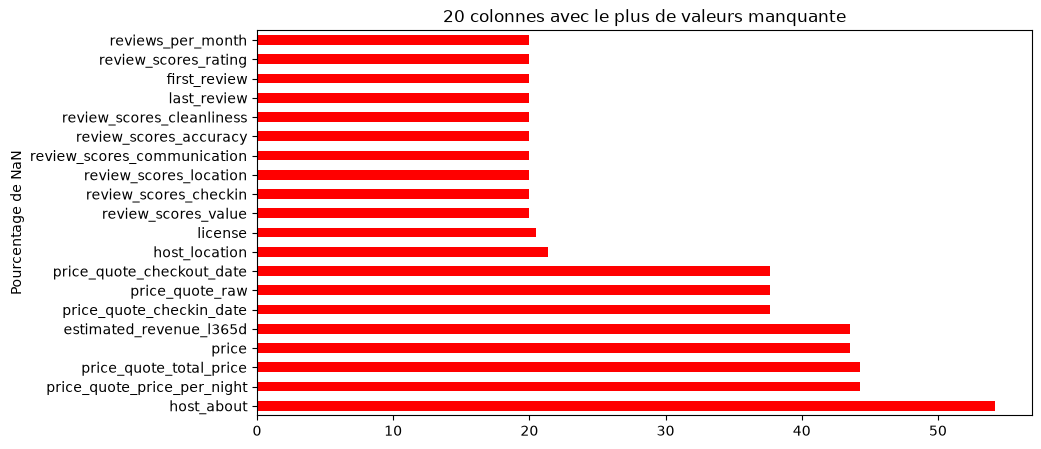

In [244]:
plt.figure(figsize=(10, 5))
val_manquantes_pct.head(20).plot(kind='barh', color='red')
plt.title('20 colonnes avec le plus de valeurs manquante')
plt.ylabel('Pourcentage de NaN')
plt.show()

On voit clairement que certaines colonnes (comme host_response_rate ou les notes très précises) sont très souvent vides; La colonne la plus intéressante ici au delà du prix est la note 'review_scores_rating' elle peut avoir un pouvoir explicatif très important

In [245]:
df['review_scores_rating']

0        4.90
1        4.72
2        4.92
3        4.92
4        4.95
         ... 
77144     NaN
77145     NaN
77146     NaN
77147     NaN
77148     NaN
Name: review_scores_rating, Length: 77149, dtype: float64

In [246]:
valeurs_manquantes_score = df['review_scores_rating'].isna()
print("Nb de logements sans note :", valeurs_manquantes_score.sum())

Nb de logements sans note : 15396


In [247]:
print(df[valeurs_manquantes_score]['number_of_reviews'].value_counts().head())

number_of_reviews
0    15396
Name: count, dtype: int64


Le nombre de reviews correspond, ceux qui ont pas de notes sont ceux qui n'ont pas de reviews (logique)

In [248]:
df_test = df[['number_of_reviews', 'reviews_per_month', 'review_scores_rating']].copy()

In [249]:
df_test['a_des_avis'] = (df_test_imput['number_of_reviews'] > 0).astype(int)

In [250]:
df_test[df_test['review_scores_rating'].isna()].head()

,number_of_reviews,reviews_per_month,review_scores_rating,a_des_avis
10,0,NaN,NaN,0
22,0,NaN,NaN,0
32,0,NaN,NaN,0
39,0,NaN,NaN,0
41,0,NaN,NaN,0


In [251]:
df_test['reviews_per_month'] = df_test['reviews_per_month'].fillna(0) 

In [252]:
df_test[df_test['review_scores_rating'].isna()].head()

,number_of_reviews,reviews_per_month,review_scores_rating,a_des_avis
10,0,0.0,NaN,0
22,0,0.0,NaN,0
32,0,0.0,NaN,0
39,0,0.0,NaN,0
41,0,0.0,NaN,0


In [253]:
mediane_score = df_test['review_scores_rating'].median()
df_test['review_scores_rating'] = df_test['review_scores_rating'].fillna(mediane_score)

On va peut-être pas faire ce genre d'imputations surtout quand la mediane est aussi élevée mais on se fait une idée

In [255]:
df_test

,number_of_reviews,reviews_per_month,review_scores_rating,a_des_avis
0,10,0.09,4.90,1
1,403,2.14,4.72,1
2,60,0.36,4.92,1
3,48,0.38,4.92,1
4,21,0.12,4.95,1
...,...,...,...,...
77144,0,0.00,4.85,0
77145,0,0.00,4.85,0
77146,0,0.00,4.85,0
77147,0,0.00,4.85,0


On a décidé que le prix allait être notre target. Avant de faire un nettoyage, on va voir comment est la variable. 

In [256]:
print(df['price'].head())

0    $272.50
1    $149.40
2    $177.75
3    $222.86
4     $57.53
Name: price, dtype: str


C'est une chaine de caractères, en effet on a un "$" devant donc il faut y remédier.

In [257]:
df_clean = df.copy()

In [258]:

df_clean['price'] = df_clean['price'].astype(str).str.replace('$', '', regex=False)
df_clean['price'] = pd.to_numeric(df_clean['price'], errors='coerce')

On vérifie que le symbole a bien disparu et que la variable est considéré comme un float

In [259]:
df_clean['price']

0        272.50
1        149.40
2        177.75
3        222.86
4         57.53
          ...  
77144    408.00
77145    720.80
77146       NaN
77147    965.00
77148    435.00
Name: price, Length: 77149, dtype: float64

On voit qu'il y a des NaN, on  va checke combien de NaN il y a et si des prix sont incohérents (nuls ou négatif)

In [127]:
print("NaN :", df_clean['price'].isna().sum(), "Prix nul :",  (df_clean['price'] <= 0).sum())

NaN : 35190 Prix nul : 0


Il a des NaN, mais on ne peut pas faire de l'imputation pour le prix donc on les supprimera. 


### Distribution du prix/ outliers
Faisons un describe() et traçons la distribution pour voir s'il y a des valeurs aberrantes.

In [128]:
df_clean['price'].describe()

count    41959.000000
mean       264.255759
std        182.671167
min         10.380000
25%        136.670000
50%        211.500000
75%        336.000000
max        999.500000
Name: price, dtype: float64

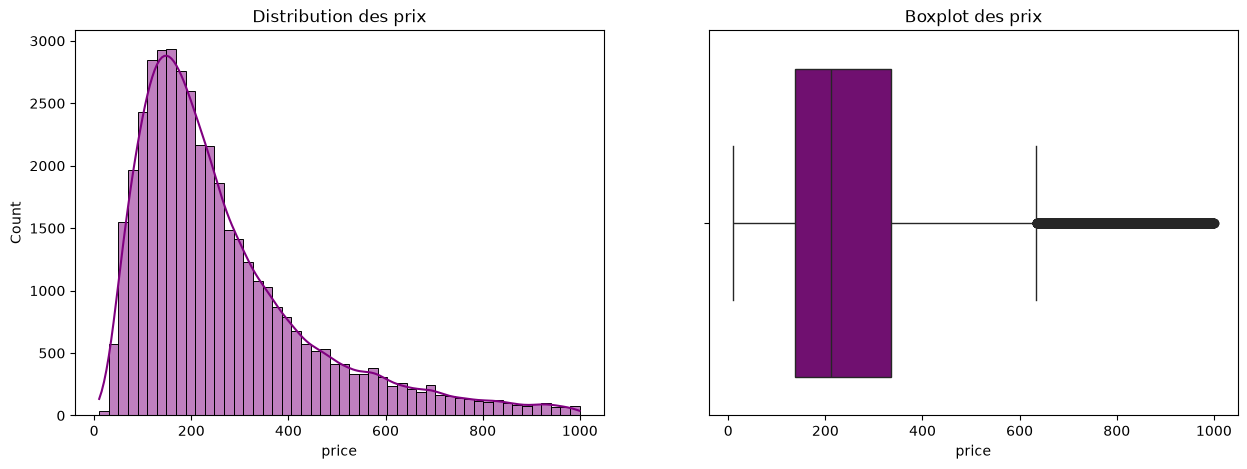

In [129]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df_clean['price'], bins=50, ax=ax[0], kde=True, color='purple')
ax[0].set_title('Distribution des prix')

sns.boxplot(x=df_clean['price'], ax=ax[1], color='purple')
ax[1].set_title('Boxplot des prix')

plt.show()

On voit que les valeurs sont très concentrées entre 0 et environ 450 euros

On peut utiliser une transformation log (suffisant vu qu'on a pas de valeur nulle) dans la pipeline pour ramener la distribution vers une courbe de Gauss.

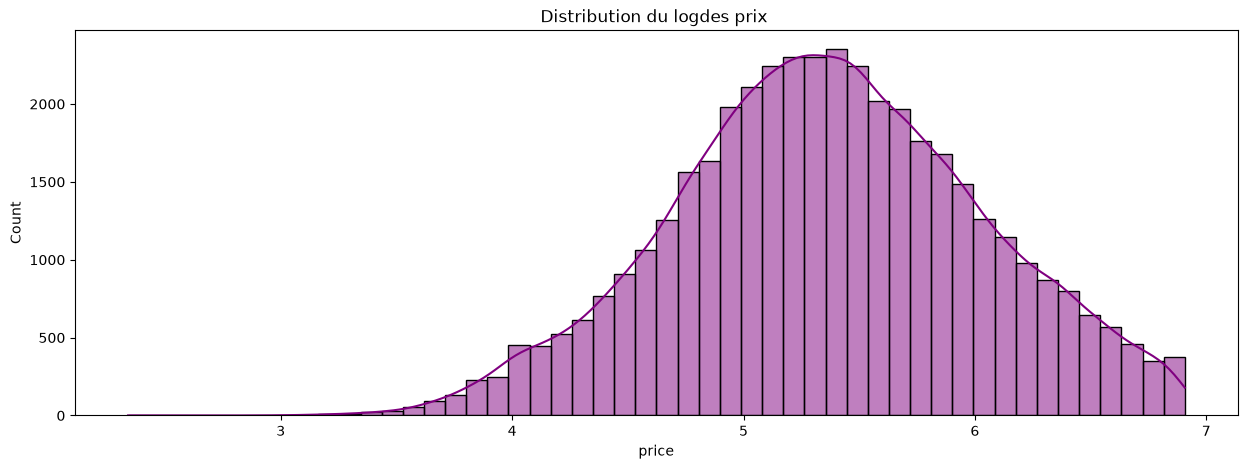

In [130]:
plt.figure(figsize=(15, 5))
sns.histplot(np.log(df_clean['price']), bins=50, kde=True, color='purple')
plt.title('Distribution du logdes prix ')
plt.show()

In [131]:
np.log(df_clean['price']).describe()

count    41959.000000
mean         5.360777
std          0.665394
min          2.339881
25%          4.917569
50%          5.354225
75%          5.817111
max          6.907255
Name: price, dtype: float64

## Groupby

On essaye de voir comment le type de chambre ou le statut de l'hôte influence le prix en utilisant des groupby.

In [132]:
df_clean.groupby('room_type')['price'].agg(['count', 'median', 'mean']).sort_values(by='median', ascending=False)

,count,median,mean
room_type,,,
Hotel room,256,314.0,372.570820
Entire home/apt,36714,219.0,272.003118
Private room,4872,154.0,204.430934
Shared room,117,58.0,87.344530


C:\Users\mehdi\AppData\Local\Temp\ipykernel_20152\3839900492.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='room_type', y='price', palette='bwr')


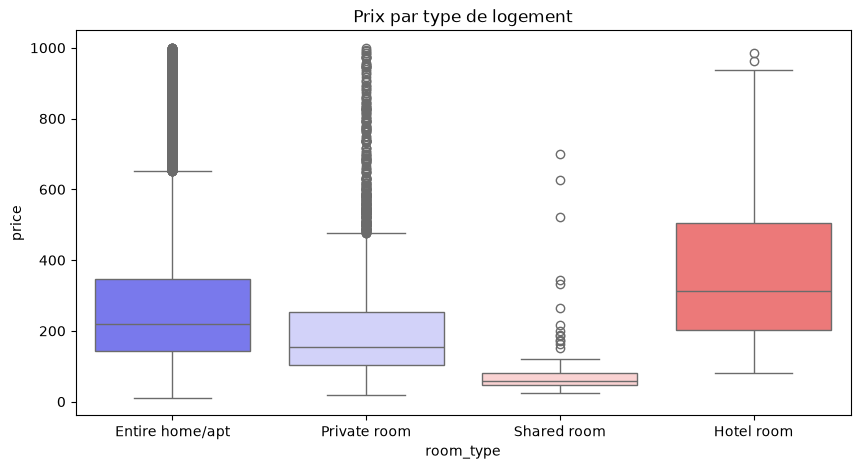

In [133]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_clean, x='room_type', y='price', palette='bwr')
plt.title('Prix par type de logement')
plt.show()


On voit que ça se concentre sur les prix entre 200 et 500 euros. On va donc filtrer pour plus de lisibilité

C:\Users\mehdi\AppData\Local\Temp\ipykernel_20152\613566247.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean[df_clean['price'] < 500], x='room_type', y='price', palette='bwr')


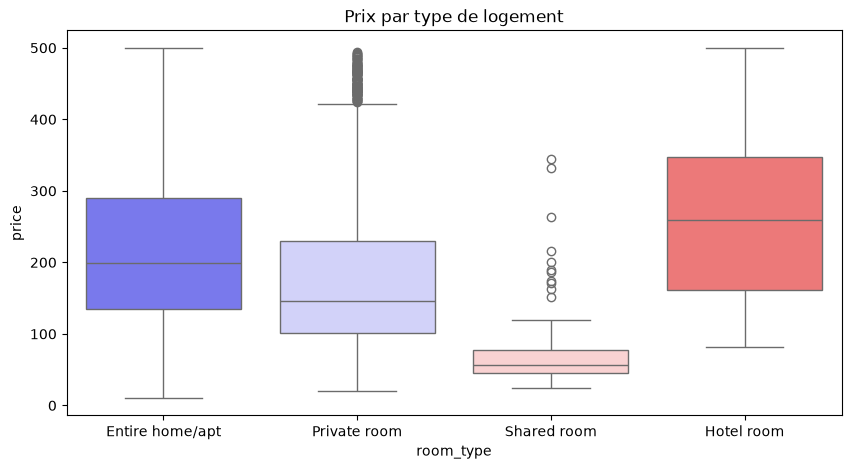

In [134]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_clean[df_clean['price'] < 500], x='room_type', y='price', palette='bwr')
plt.title('Prix par type de logement')
plt.show()

C:\Users\mehdi\AppData\Local\Temp\ipykernel_20152\1788340950.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_clean, x='is_superhost', y='price', estimator=np.median, errorbar=None, palette='bwr')


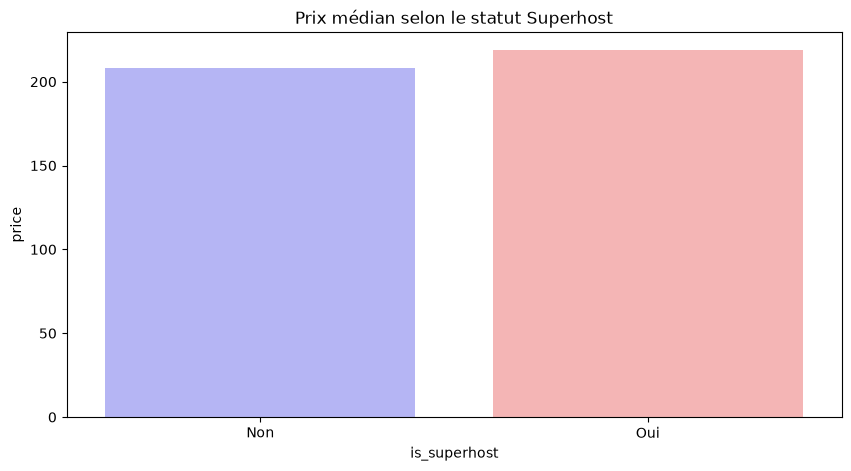

In [135]:
df_clean['is_superhost'] = df_clean['host_is_superhost'].map({'t': 'Oui', 'f': 'Non'})

plt.figure(figsize=(10, 5))
sns.barplot(data=df_clean, x='is_superhost', y='price', estimator=np.median, errorbar=None, palette='bwr')
plt.title('Prix médian selon le statut Superhost')
plt.show()

## analyse géo

On regarde les quartiers par prix (nuit) et on fait un mapping spatial de la carte de paris avec un scatter plot.

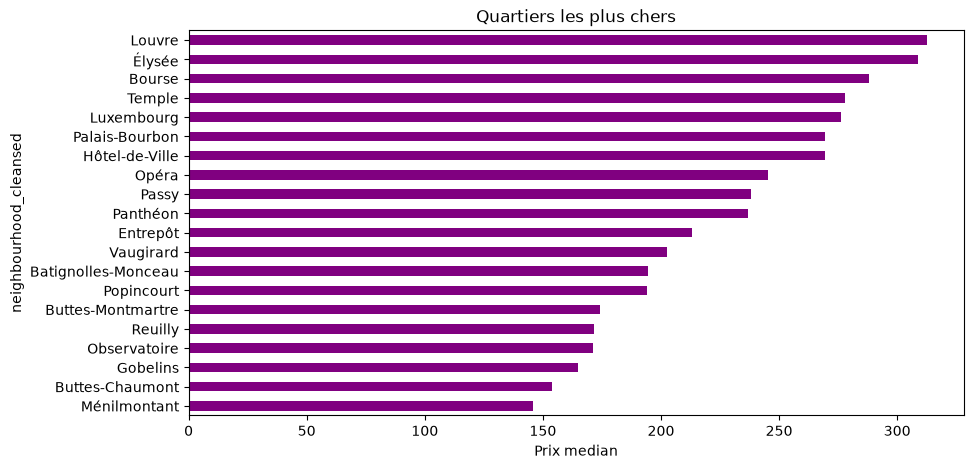

In [136]:

quartiers_prix = df_clean.groupby('neighbourhood_cleansed')['price'].median().sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 5))
quartiers_prix.sort_values().plot(kind='barh', color='purple')
plt.title('Quartiers les plus chers')
plt.xlabel('Prix median')
plt.show()

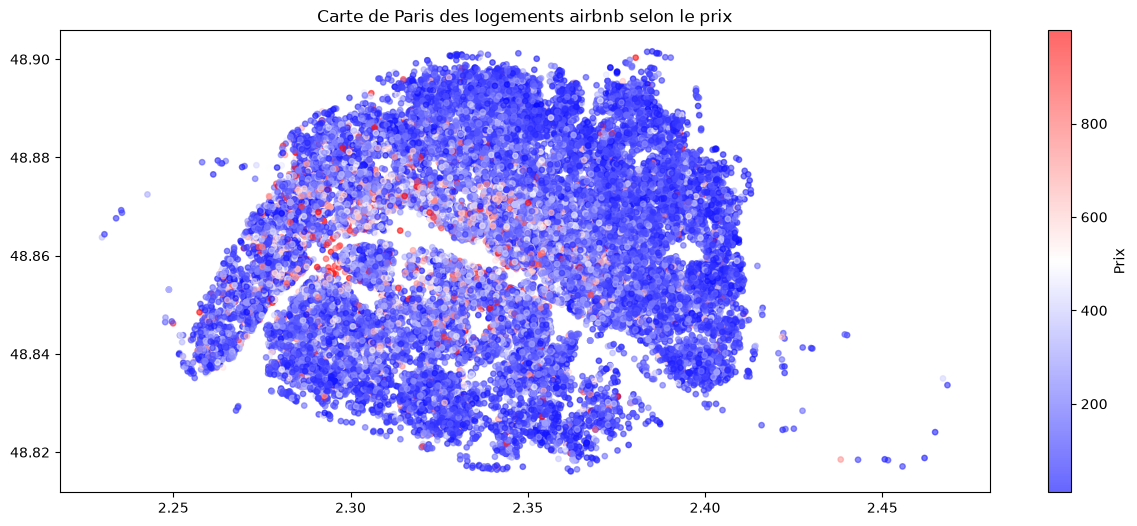

In [137]:
plt.figure(figsize=(15, 6))
scatter = plt.scatter(
    df_clean['longitude'], 
    df_clean['latitude'], 
    c=df_clean['price'], 
    cmap='bwr', 
    alpha=0.6, 
    s=15
)
plt.colorbar(scatter, label='Prix')
plt.title('Carte de Paris des logements airbnb selon le prix')
plt.show()

Comme vu lors de la partie distribution les valeurs sont concentrées entre 0 et 450 euros, il faudrait faire un masque pour faire parler le graphique et les contrastes de prix

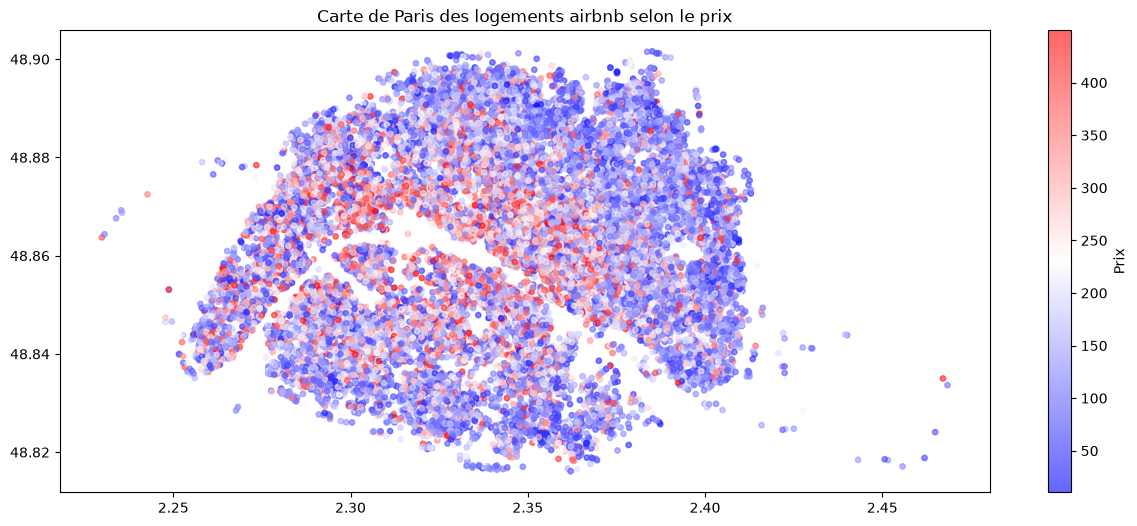

In [138]:
mask = df_clean['price'] < 450

plt.figure(figsize=(15, 6))
scatter = plt.scatter(
    df_clean[mask]['longitude'], 
    df_clean[mask]['latitude'], 
    c=df_clean[mask]['price'], 
    cmap='bwr', 
    alpha=0.6, 
    s=15
)
plt.colorbar(scatter, label='Prix')
plt.title('Carte de Paris des logements airbnb selon le prix')
plt.show()

On peut voir sans trop de surprises que les prix les plus élevés sont regroupés au centre de Paris dans les premiers arrondissements

## analyse corrélations

on essaye de voir les liens linéaires avec le prix

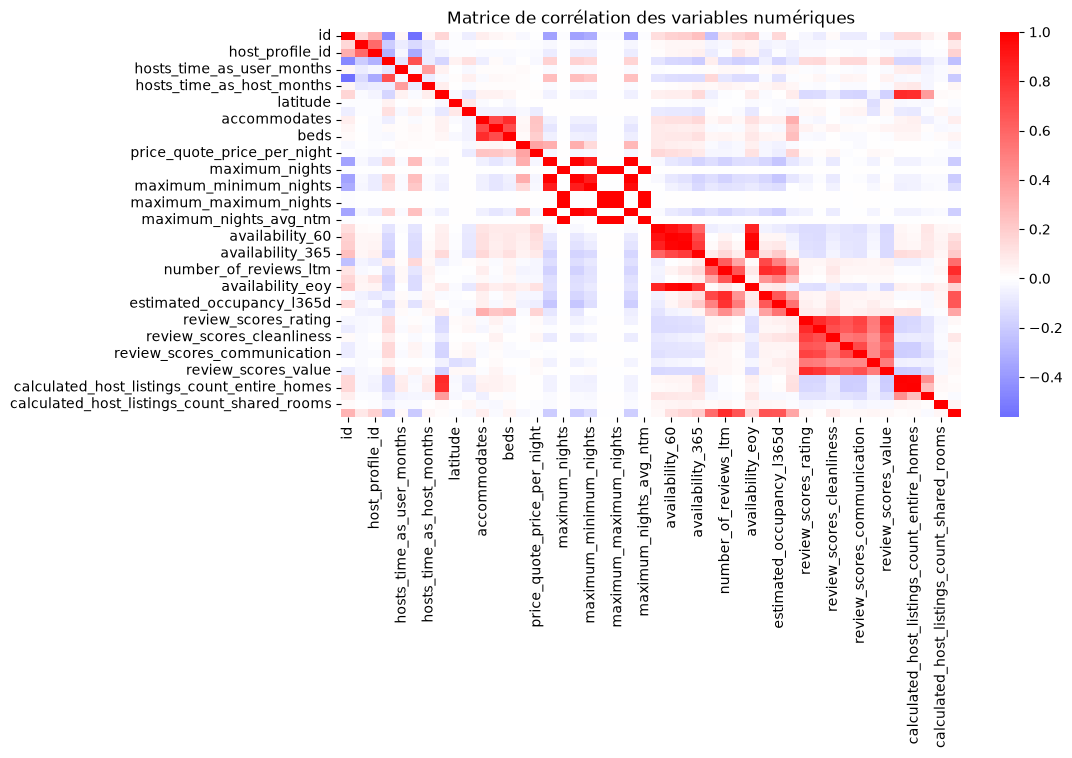

In [139]:
plt.figure(figsize=(10, 5))

corr = df[numeric_cols].corr()
sns.heatmap(corr, cmap="bwr", center=0, annot=False)
plt.title("Matrice de corrélation des variables numériques")
plt.show()

On avait au début retrouvé quelques variables numériques intérssantes comme 'accommodates', 'bedrooms', 'number_of_reviews', 'review_scores_rating'

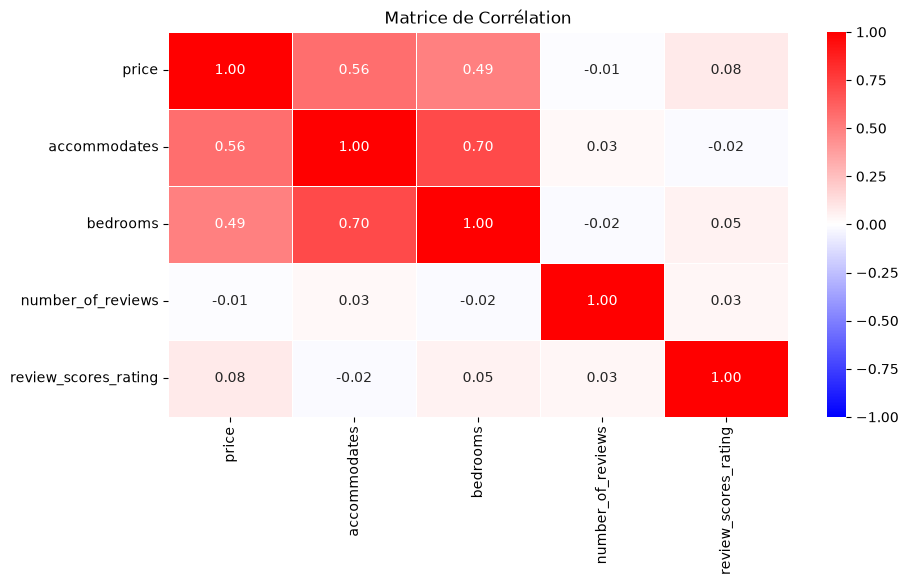

In [140]:
cols_num = ['price', 'accommodates', 'bedrooms', 'number_of_reviews', 'review_scores_rating']

corr_matrix = df_clean[cols_num].corr()

plt.figure(figsize=(10, 5))
sns.heatmap(corr_matrix, annot=True, cmap='bwr', vmin=-1, vmax=1, fmt='.2f', linewidths=0.5)
plt.title('Matrice de Corrélation')
plt.show()

On voit que 'accommodates' et 'bedrooms' sont effectivement assez corrélées au prix. Les variables sont aussi très corrélées entre elles et c'est logique, plus la capacité est grande plus il peut y avoir de chambres et inversement.

## Variable amenities

On avait vu la variable 'amenities' qui listait les équipements de chaque appartement mais qui avait beaucoup trop de modalités.

In [260]:
print(df_clean['amenities'])

0        ["Iron", "Children\u2019s books and toys", "Sm...
1        ["Free washer \u2013 In unit", "Hot water", "R...
2        ["Hot water", "Refrigerator", "Wifi", "Dedicat...
3        ["Coffee maker: Nespresso, pour-over coffee", ...
4        ["Hot water", "Refrigerator", "Wifi", "Dedicat...
                               ...                        
77144    ["Hot water", "Paid parking lot off premises",...
77145    ["Outdoor furniture", "Hot water", "Wifi", "Bo...
77146    ["Iron", "Coffee maker", "Hangers", "TV", "Hot...
77147    ["Hot water", "Refrigerator", "Wifi", "Dedicat...
77148    ["Hot water", "Refrigerator", "Wifi", "Etherne...
Name: amenities, Length: 77149, dtype: str


En fait on comprend que chaque observation contient une liste d'équipements, il faudrait pouvoir les extraire individuellement et peut-être en faire des variables à part entière en les Onehot encodant. Neanmoins il faut vérifier si les modalités n'en restent pas moins toujours élevées 

In [261]:
def convertir_en_liste(x):
        if pd.isna(x):
            return []
        texte_nettoye = str(x).replace('[', '').replace(']', '').replace('"', '').replace("'", "")
        return [equipement.strip() for equipement in texte_nettoye.split(',') if equipement.strip() != ""]

equipement_extract = [item for list in df_clean['amenities'].dropna().apply(convertir_en_liste) for item in list]
equipement_extract

['Iron',
 'Children\\u2019s books and toys',
 'Smoke alarm',
 'Hangers',
 'Hot water',
 'Cooking basics',
 'Dishes and silverware',
 'Luggage dropoff allowed',
 'Hair dryer',
 'Washer',
 'Wifi',
 'Self check-in',
 'Smart lock',
 'Kitchen',
 'Paid parking off premises',
 'Free washer \\u2013 In unit',
 'Hot water',
 'Refrigerator',
 'Wifi',
 'Dedicated workspace',
 'Kitchen',
 'Iron',
 'Dishes and silverware',
 'Cooking basics',
 'Host greets you',
 'Essentials',
 'Bed linens',
 'Shampoo',
 'Microwave',
 'Coffee maker',
 'Smoke alarm',
 'Paid parking off premises',
 'Stove',
 'Hangers',
 'Hair dryer',
 'Heating',
 'Extra pillows and blankets',
 'Oven',
 'Dryer',
 'TV with standard cable',
 'Hot water',
 'Refrigerator',
 'Wifi',
 'Dedicated workspace',
 'Cleaning products',
 'Kitchen',
 'Iron',
 'TV',
 'Dishes and silverware',
 'Cooking basics',
 'Freezer',
 'Host greets you',
 'Essentials',
 'Bed linens',
 'Shampoo',
 'Single level home',
 'Central heating',
 'Microwave',
 'Baking sheet

In [262]:
equipement_counts = Counter(equipement_extract)
equipement_counts.most_common(10)

[('Kitchen', 71834),
 ('Wifi', 70264),
 ('Hot water', 60291),
 ('Smoke alarm', 58395),
 ('Hair dryer', 56866),
 ('Essentials', 56152),
 ('Dishes and silverware', 53555),
 ('Bed linens', 52599),
 ('Iron', 51718),
 ('Hangers', 51118)]

In [263]:
print("Nombre d'équipements :", len((equipement_counts)))

Nombre d'équipements : 6697


On voit que malgré tout il y a beaucoup trop de modalités pour penser à onehot encoder. On pourra soit se limiter aux plus communs ou trouver une méthode pour en regrouper certains

# Variable accomodate et bedroom



<Axes: xlabel='bedrooms'>

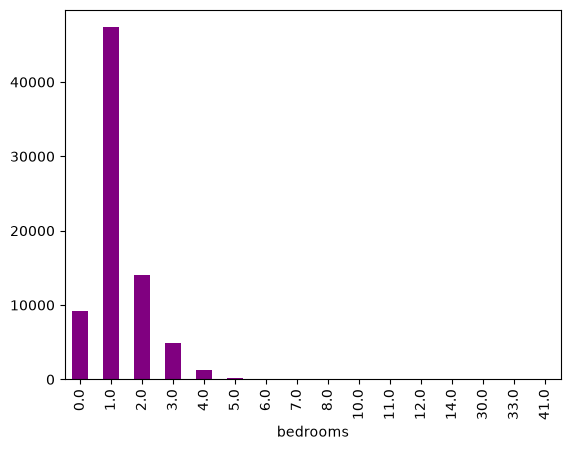

In [215]:
df['bedrooms'].value_counts().sort_index().plot(kind='bar', color='purple')

<Axes: xlabel='accommodates'>

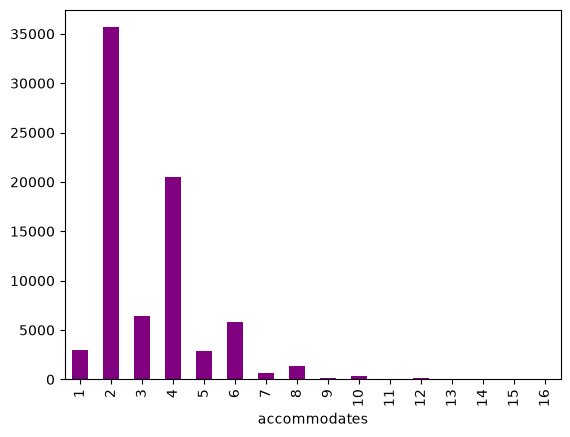

In [216]:
df['accommodates'].value_counts().sort_index().plot(kind='bar', color='purple')

In [225]:
df['bedrooms'].isna().sum()

np.int64(25)

In [226]:
df['accommodates'].isna().sum()

np.int64(0)

In [224]:
groupby_lits = df.groupby('accommodates')['beds'].median()
groupby_lits

accommodates
1     1.0
2     1.0
3     2.0
4     2.0
5     3.0
6     3.0
7     4.0
8     4.0
9     5.0
10    5.0
11    7.0
12    6.0
13    7.0
14    7.0
15    9.0
16    9.0
Name: beds, dtype: float64

La relation est logique, même s'il y a très peu de NaN on peut penser à une imputation par accomodates

# EDA Calendar

In [145]:
df = pd.read_parquet(chemin_airbnb / "calendar.parquet")
print("Le dataset contient", df.shape[0], "lignes et  ", df.shape[1], "colonnes.")

Le dataset contient 28162159 lignes et   5 colonnes.


In [146]:
df.head()

,listing_id,date,available,minimum_nights,maximum_nights
0,3109,2026-09-19,f,2,30
1,3109,2026-09-20,f,2,30
2,3109,2026-09-21,t,2,30
3,3109,2026-09-22,t,2,30
4,3109,2026-09-23,f,2,30


In [147]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 28162159 entries, 0 to 28162158
Data columns (total 5 columns):
 #   Column          Dtype
---  ------          -----
 0   listing_id      int64
 1   date            str  
 2   available       str  
 3   minimum_nights  int64
 4   maximum_nights  int64
dtypes: int64(3), str(2)
memory usage: 1.3 GB


In [148]:
for column in df.columns:
    if df[column].nunique() <= 1:
        df.drop(columns=column, inplace=True)
        print(f'{column} - supprimée')

    else:
        print(f'\n{column}')
        print('Nombre de modalités :', df[column].nunique())
        print('Nombre de valeurs manquantes :', df[column].isna().sum())
        print('types :', df[column].dropna().map(type).unique())

        print('Modalités les plus fréquentes :')
        print(df[column].value_counts().head(5))

        print('Modalités les moins fréquentes :')
        print(df[column].value_counts().tail(5))


listing_id
Nombre de modalités : 77149
Nombre de valeurs manquantes : 0
types : [<class 'int'>]
Modalités les plus fréquentes :
listing_id
20562660               370
1044871863208022528    370
1044872043415219527    370
1044872043937449392    370
1035431396081522273    370
Name: count, dtype: int64
Modalités les moins fréquentes :
listing_id
1775393921523535909    365
1775399195823385727    365
1775408419703264483    365
1775445409530547879    365
1775503305421490832    365
Name: count, dtype: int64

date
Nombre de modalités : 372
Nombre de valeurs manquantes : 0
types : [<class 'str'>]
Modalités les plus fréquentes :
date
2026-09-24    77149
2026-09-25    77149
2026-09-26    77149
2026-09-27    77149
2026-09-28    77149
Name: count, dtype: int64
Modalités les moins fréquentes :
date
2027-09-20    26934
2027-09-21    11361
2026-09-17     2153
2027-09-22      792
2027-09-23        3
Name: count, dtype: int64

available
Nombre de modalités : 2
Nombre de valeurs manquantes : 0
types : [<

La variable available peut-être soit transformée en catégorielle en onehot encodant soit on peut faire un calcul pour mesurer le taux d'occupation. On veut éviter de multiplier les colonnes et on va plutôt calculer le taux

In [149]:

df['est_dispo'] = (df['available'] == 't').astype(int)

stats = df.groupby('listing_id').agg(
    jours_totaux=('date', 'count'),
    jours_dispos=('est_dispo', 'sum')
).reset_index()

stats['taux_occupation'] = 1 - (stats['jours_dispos'] / stats['jours_totaux'])

print(stats[['listing_id', 'taux_occupation']])

                listing_id  taux_occupation
0                     3109         0.038356
1                     7397         0.408219
2                     9952         0.775342
3                    11265         0.268493
4                    11487         0.252055
...                    ...              ...
77144  1775393921523535909         0.246575
77145  1775399195823385727         0.715068
77146  1775408419703264483         1.000000
77147  1775445409530547879         0.002740
77148  1775503305421490832         0.041096

[77149 rows x 2 columns]


In [150]:
val_manquantes = df.isna().sum()
val_manquantes_pct = ((val_manquantes[val_manquantes > 0] / len(df)) * 100).sort_values(ascending=False)
val_manquantes_pct


Series([], dtype: float64)

Pas grand chose à dire sur ce dataframe, pas de NaN et imputation assez logique et claire

# EDA Stations

In [151]:
df = pd.read_parquet(chemin_poi / "train_station_scnf.parquet")
print("Le dataset contient", df.shape[0], "lignes et  ", df.shape[1], "colonnes.")

Le dataset contient 1002 lignes et   30 colonnes.


In [152]:
df.head()

,Geo Point,Geo Shape,OBJECTID_1,codeunique,nom_long,nom_so_gar,nom_su_gar,id_ref_ZdC,nom_ZdC,id_ref_ZdA,...,tertrain,terrer,termetro,tertram,terval,exploitant,idf,principal,x,y
0,"48.88218913760796, 2.70601418111842","{""coordinates"": [2.70601418111842, 48.88218913...",5,3,Lagny-Thorigny,NaN,NaN,68494,Lagny - Thorigny,427872,...,0,0,0,0,0,SNCF,1,0,678439.8038,6.864726e+06
1,"48.83964551726303, 2.655130086641314","{""coordinates"": [2.655130086641314, 48.8396455...",7,7,Torcy,NaN,NaN,68129,Torcy,43207,...,0,0,0,0,0,RATP,1,0,674687.4504,6.860010e+06
2,"48.79565482051668, 2.6503876698084805","{""coordinates"": [2.650387669808481, 48.7956548...",9,10,Roissy-en-Brie,NaN,NaN,67839,Roissy-en-Brie,46568,...,0,0,0,0,0,SNCF,1,0,674317.7148,6.855121e+06
3,"48.77077891616031, 2.690252782201096","{""coordinates"": [2.690252782201096, 48.7707789...",10,11,Ozoir-la-Ferrière,NaN,NaN,462934,Ozoir-la-Ferrière,462901,...,0,0,0,0,0,SNCF,1,0,677235.3132,6.852342e+06
4,"48.960226490735955, 2.9500603827528087","{""coordinates"": [2.950060382752809, 48.9602264...",13,16,Trilport,NaN,NaN,68984,Trilport,47962,...,0,0,0,0,0,SNCF,1,0,696343.0315,6.873365e+06


In [153]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1002 entries, 0 to 1001
Data columns (total 30 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Geo Point   1002 non-null   str    
 1   Geo Shape   1002 non-null   str    
 2   OBJECTID_1  1002 non-null   int64  
 3   codeunique  1002 non-null   int64  
 4   nom_long    1002 non-null   str    
 5   nom_so_gar  68 non-null     str    
 6   nom_su_gar  29 non-null     str    
 7   id_ref_ZdC  1002 non-null   int64  
 8   nom_ZdC     1002 non-null   str    
 9   id_ref_ZdA  1002 non-null   int64  
 10  nom_ZdA     1002 non-null   str    
 11  idrefliga   1002 non-null   str    
 12  idrefligc   1002 non-null   str    
 13  res_com     1002 non-null   str    
 14  mode_       1002 non-null   str    
 15  train       1002 non-null   int64  
 16  rer         1002 non-null   int64  
 17  metro       1002 non-null   int64  
 18  tramway     1002 non-null   int64  
 19  val         1002 non-null   int64  
 2

In [154]:
for column in df.columns:
    if df[column].nunique() <= 1:
        df.drop(columns=column, inplace=True)
        print(f'{column} - supprimée')

    else:
        print(f'\n{column}')
        print('Nombre de modalités :', df[column].nunique())
        print('Nombre de valeurs manquantes :', df[column].isna().sum())
        print('types :', df[column].dropna().map(type).unique())

        print('Modalités les plus fréquentes :')
        print(df[column].value_counts().head(5))

        print('Modalités les moins fréquentes :')
        print(df[column].value_counts().tail(5))


Geo Point
Nombre de modalités : 1002
Nombre de valeurs manquantes : 0
types : [<class 'str'>]
Modalités les plus fréquentes :
Geo Point
48.88218913760796, 2.70601418111842       1
48.83964551726303, 2.655130086641314      1
48.79565482051668, 2.6503876698084805     1
48.77077891616031, 2.690252782201096      1
48.960226490735955, 2.9500603827528087    1
Name: count, dtype: int64
Modalités les moins fréquentes :
Geo Point
48.66531992340216, 2.362618263949531     1
48.897586648407284, 2.223738843023636    1
48.88224373133741, 2.4673561174182512    1
48.746978700693774, 2.372839696785623    1
48.79305491267365, 2.34936523945399      1
Name: count, dtype: int64

Geo Shape
Nombre de modalités : 1002
Nombre de valeurs manquantes : 0
types : [<class 'str'>]
Modalités les plus fréquentes :
Geo Shape
{"coordinates": [2.70601418111842, 48.88218913760796], "type": "Point"}      1
{"coordinates": [2.655130086641314, 48.83964551726303], "type": "Point"}     1
{"coordinates": [2.650387669808481, 48

Le plus intéressant dans ce dataset est la longitude et latitude des stations qui peut être croisée avec celle dans listing pour calculer la distance notamment

In [155]:
coords_stations = df['Geo Point'].str.split(',', expand=True).astype(float)

C:\Users\mehdi\AppData\Local\Temp\ipykernel_20152\1658808776.py:2: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scatter = plt.scatter(


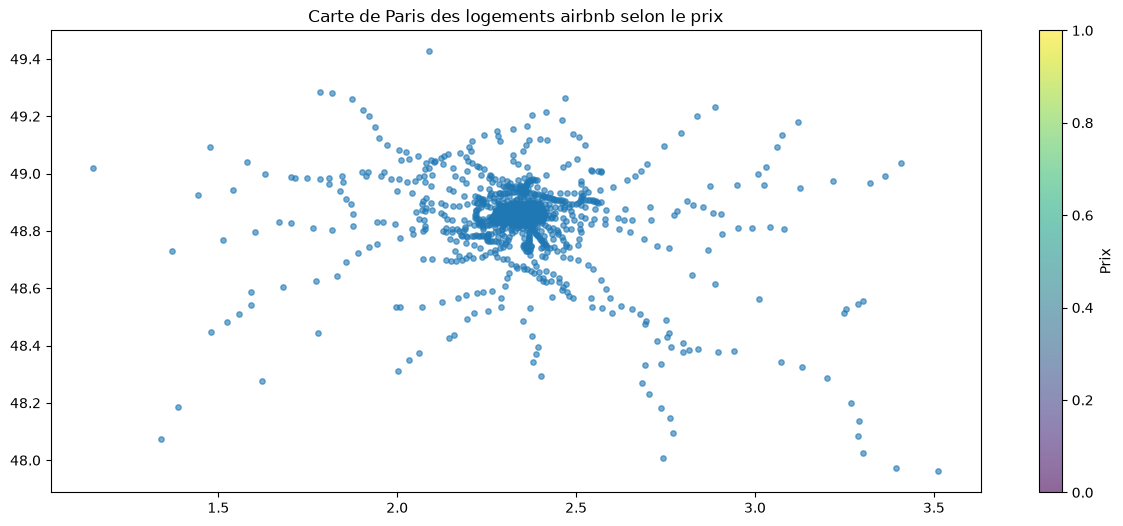

In [156]:
plt.figure(figsize=(15, 6))
scatter = plt.scatter(
    coords_stations[1], 
    coords_stations[0],  
    cmap='bwr', 
    alpha=0.6, 
    s=15
)
plt.colorbar(scatter, label='Prix')
plt.title('Carte de Paris des logements airbnb selon le prix')
plt.show()

Je décide de faire une distance simplement euclidienne pour tester avec un knn

In [157]:
df_listings = pd.read_parquet(chemin_airbnb / "listings_detailled.parquet")

In [158]:
rad_stations = np.radians(coords_stations)
rad_listings = np.radians(df_listings[['latitude', 'longitude']].values)

En gros on va organiser dans un arbre les coordonnées des stations de métro

In [159]:
from scipy.spatial import cKDTree
arbre = cKDTree(rad_stations) 

En gros on va chercher pour listings LE plus proche voisin selon une distance euclidienne, 1 seule station suffit vu que l'important c'est pas forcément la station en elle même mais avoir le métro à côté

In [160]:
arbre.query(rad_listings, k=1)

(array([4.04460958e-05, 3.74035106e-05, 5.63861893e-05, ...,
        1.12079612e-05, 4.50192161e-05, 1.77555196e-05], shape=(77149,)),
 array([900, 105, 689, ..., 108, 297, 101], shape=(77149,)))

C'est un tupple avec en premier l'array de la distance du logement (listings) à la station, et en deuxième la position/ligne de la dite station dans sa table. On peut comme ça avoir l'id et la poser face au logement

In [161]:
len(arbre.query(rad_listings, k=1))

2

In [162]:
distance, index_stations = arbre.query(rad_listings, k=1)

df_listings['distance_metro_m'] = np.round(distance * 6371000, 1)

On aura juste à les merge